<a href="https://colab.research.google.com/github/SummerSnow-flake/NS/blob/Term_project/ecg_arrhythmia_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ECG Arrhytmia Classification
### MIT-BIH Arrhythmia Dataset – Perceptron, MLP, 1D CNN comparison

**Dataset:** https://www.kaggle.com/datasets/shayanfazeli/heartbeat

## 0. Imports



In [ ]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, Conv1D, MaxPooling1D, GlobalAveragePooling1D
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (classification_report, confusion_matrix,
                             f1_score, accuracy_score, precision_score, recall_score)

# Seed
Seed = 42
np.random.seed(Seed)
tf.random.set_seed(Seed)

---
## 1. Load dataset

Each row = one heartbeat (187 ECG values + 1 classification).

In [ ]:
# Load dataset

from sklearn.model_selection import train_test_split

# Read CSV files and join together
train_df = pd.read_csv('/content/mitbih_train.csv', header=None)
test_df  = pd.read_csv('/content/mitbih_test.csv',  header=None)
all_df   = pd.concat([train_df, test_df], ignore_index=True)
print("Combined dataset shape:", all_df.shape)  # Expected: (109446, 188)


# Separate heartbeat (X) and class (y)
X_all = all_df.iloc[:, :-1].values # 187 ECG time steps (ignore last column - classification)
y_all = all_df.iloc[:, -1].values.astype(int) # classes 0-4 (to int)

# All data
print("\nShape:")
print("X shape:", X_all.shape)
print("y shape:", y_all.shape)



Combined dataset shape: (109670, 188)

Shape:
X shape: (109670, 187)
y shape: (109670,)


/tmp/ipykernel_4599/1747490494.py:14: RuntimeWarning: invalid value encountered in cast
  y_all = all_df.iloc[:, -1].values.astype(int) # classes 0-4 (to int)


---
## 2. Data analysis

In [ ]:
# Example data
print("Example data:\n", all_df.head(3))
print("\nExample classes:\n", y_train[:50])
print("\nAll data count/shape:\n", all_df.shape)
print("\nUnique classes:\n", all_df.iloc[:, -1].unique())


Example data:
         0         1         2         3         4         5         6    \
0  0.977941  0.926471  0.681373  0.245098  0.154412  0.191176  0.151961   
1  0.960114  0.863248  0.461538  0.196581  0.094017  0.125356  0.099715   
2  1.000000  0.659459  0.186486  0.070270  0.070270  0.059459  0.056757   

        7         8         9    ...  178  179  180  181  182  183  184  185  \
0  0.085784  0.058824  0.049020  ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
1  0.088319  0.074074  0.082621  ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   
2  0.043243  0.054054  0.045946  ...  0.0  0.0  0.0  0.0  0.0  0.0  0.0  0.0   

   186  187  
0  0.0  0.0  
1  0.0  0.0  
2  0.0  0.0  

[3 rows x 188 columns]

Example classes:
 [1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 4 4 0
 0 1 4 0 0 0 0 2 0 0 2 0 0]

All data count/shape:
 (109446, 188)

Unique classes:
 [0. 1. 2. 3. 4.]


In [ ]:
# Class dictionary
class_names = {
    0: 'Normal',
    1: 'Supraventricular',
    2: 'Ventricular',
    3: 'Fusion',
    4: 'Unknown'
}
colors_cls = ['#2196F3', '#FF5722', '#4CAF50', '#FF9800', '#9C27B0']

# Remove rows with labels outside 0–4
mask = (y_all >= 0) & (y_all <= 4)
X_all = X_all[mask]
y_all = y_all[mask]
print("After cleaning count:", X_all.shape[0]) # 109446 original count


After cleaning count: 109669


Class distribution in the all data:
--------------------------------------------------
  Class 0 : 90812 samples (82.8%)
  Class 1 : 2779 samples (2.5%)
  Class 2 : 7236 samples (6.6%)
  Class 3 : 803 samples (0.7%)
  Class 4 : 8039 samples (7.3%)


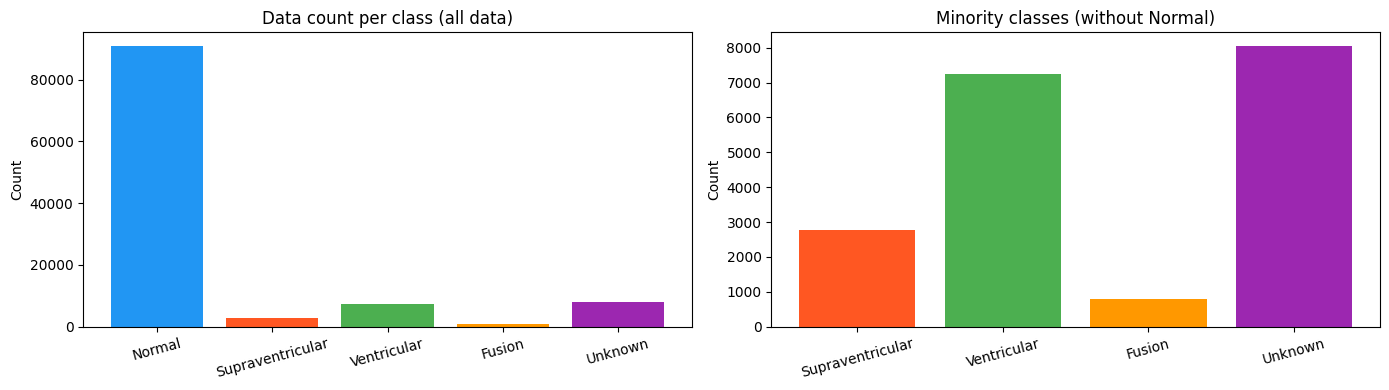

In [ ]:
# Class distribution
unique, counts = np.unique(y_all, return_counts=True)
print("Class distribution in the all data:")
print("-" * 50)
for unique_class, count_number in zip(unique, counts):
    percent = 100 * count_number / len(y_all)
    print(f"  Class {unique_class} : {count_number} samples ({percent:.1f}%)")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar([class_names[i] for i in unique], counts, color=colors_cls)
axes[0].set_title('Data count per class (all data)')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=15)

axes[1].bar([class_names[i] for i in unique[1:]], counts[1:], color=colors_cls[1:])
axes[1].set_title('Minority classes (without Normal)')
axes[1].set_ylabel('Count')
axes[1].tick_params(axis='x', rotation=15)

plt.tight_layout()
plt.savefig('class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()


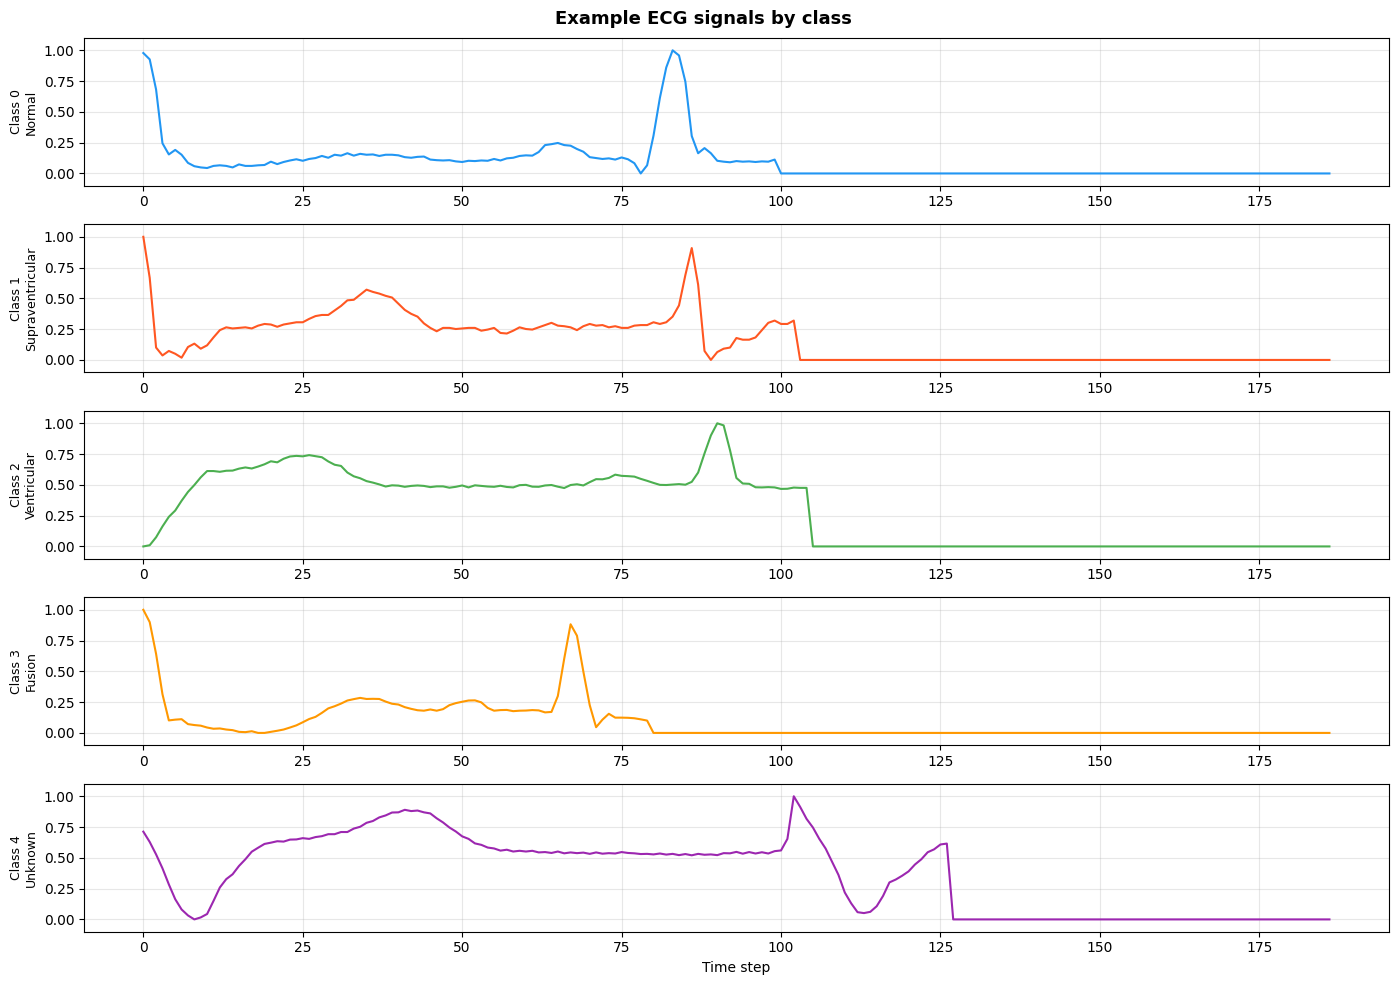

In [ ]:
# Visualiasation of ECG signals by class
fig, axes = plt.subplots(5, 1, figsize=(14, 10))

for class_id in range(5):
    idx = np.where(y_all == class_id)[0][0]
    signal = X_all[idx]
    axes[class_id].plot(signal, color=colors_cls[class_id], linewidth=1.5)
    axes[class_id].set_ylabel(f'Class {class_id}\n{class_names[class_id]}', fontsize=9)
    axes[class_id].set_ylim(-0.1, 1.1)
    axes[class_id].grid(True, alpha=0.3)

axes[-1].set_xlabel('Time step')
fig.suptitle('Example ECG signals by class', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('example_signals.png', dpi=150, bbox_inches='tight')
plt.show()

## 3. Data Preprocessing

### 3a. Training / Testing / Validation set split – 70 % / 15 % / 15 %

In [ ]:
# Training set (70%)
X_train_raw, X_temp, y_train_raw, y_temp = train_test_split(
    X_all, y_all, test_size=0.30,
    random_state=Seed, # seed - same split every run
    stratify=y_all  # maintain ratio of classes in each set
)

# Testing and Validation set (50:50 of temp)
X_val_raw, X_test_raw, y_val_raw, y_test_raw = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=Seed, stratify=y_temp
)

# Shape
print("\nShape:")
print("X_train:", X_train_raw.shape, "  y_train:", y_train_raw.shape)
print("X_test: ", X_test_raw.shape,  "  y_test: ", y_test_raw.shape)
print("X_val: ", X_val_raw.shape,  "  y_val: ", y_val_raw.shape)


Shape:
X_train: (76768, 187)   y_train: (76768,)
X_test:  (16451, 187)   y_test:  (16451,)
X_val:  (16450, 187)   y_val:  (16450,)


### 3b. Normalisation (per-sample MinMax):
- scale signal values to [0-1] range

In [ ]:
# Signal statistics before normalisation
print("Signal statistics (before normalisation):")
print(f"  Min:  {X_all.min():.4f}")
print(f"  Max:  {X_all.max():.4f}")
print(f"  Mean: {X_all.mean():.4f}") # mean value
print(f"  Std:  {X_all.std():.4f}")  # standard deviation

Signal statistics (before normalisation):
  Min:  0.0000
  Max:  1.0000
  Mean: 0.1741
  Std:  0.2262


In [ ]:
# Per-sample MinMax normalisation
def normalise_signals(X):
    """Scales each row to [0-1] range."""
    X_max = X.max(axis=1, keepdims=True)
    return X / (X_max + 1e-8)   # +1e-8 to prevent zerodivison

X_train_norm = normalise_signals(X_train_raw)
X_val_norm   = normalise_signals(X_val_raw)
X_test_norm  = normalise_signals(X_test_raw)

print(f"Range after normalisation: [{X_train_norm.min():.4f}, {X_train_norm.max():.4f}]")

Range after normalisation: [0.0000, 1.0000]


### 3c. One-hot encoding of classes
- data is not ordinal, we have independent classes -> one-hot encoding needed

In [ ]:
# One-hot encoding
y_train_cat = to_categorical(y_train_raw, num_classes=5)
y_val_cat   = to_categorical(y_val_raw,   num_classes=5)
y_test_cat  = to_categorical(y_test_raw,  num_classes=5)

print("Shapes after one-hot encoding:")
print("  y_train_cat:", y_train_cat.shape)
print("  y_val_cat:  ", y_val_cat.shape)
print("  y_test_cat: ", y_test_cat.shape)

Shapes after one-hot encoding:
  y_train_cat: (76768, 5)
  y_val_cat:   (16450, 5)
  y_test_cat:  (16451, 5)


### 3d. Signal Augmentation
- applied on training sets of minority classes (because of imbalanced data)
- not applied on class 4 (unknown - mix of signals)


In [ ]:
def augment(signal, noise=0.01, max_shift=5):
    """Add Gaussian noise + random circular time shift."""
    return np.roll(signal + np.random.normal(0, noise, signal.shape),
                   np.random.randint(-max_shift, max_shift))

X_aug_list, y_aug_list = [X_train_norm], [y_train_raw]

for class_number in [1, 2, 3]:          # minority classes
    idx = np.where(y_train_raw == class_number)[0]
    X_aug_list.append(np.array([augment(X_train_norm[i]) for i in idx]))
    y_aug_list.append(np.full(len(idx), class_number))
    print(f"  Class {class_number}: {len(idx)} added samples")

X_train_aug = np.vstack(X_aug_list)
y_train_aug = np.concatenate(y_aug_list)

# Shuffle
idx_sh = np.random.permutation(len(X_train_aug))
X_train_aug = X_train_aug[idx_sh]
y_train_aug = y_train_aug[idx_sh]
y_train_aug_cat = to_categorical(y_train_aug, 5)

print(f"\nTraining set before augmentation: {X_train_norm.shape}")
print(f"Training set after  augmentation: {X_train_aug.shape}")

  Class 1: 1946 added samples
  Class 2: 5065 added samples
  Class 3: 562 added samples

Training set before augmentation: (76768, 187)
Training set after  augmentation: (84341, 187)


---
## 4. Callbacks

- EarlyStopping - stops training if val_loss does not improve for certain number of epochs
- ReduceLROnPlateau - decreases learning rate if val_loss stagnates

In [ ]:
def get_callbacks(patience=5):
    return [
        # EarlyStopping - if val_loss does not improve over 5 epochs
        EarlyStopping(
            monitor='val_loss',
            patience=patience,
            restore_best_weights=True,
            verbose=1
        ),
        # ReduceLROnPlateau
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,      # newLR = former * 0.5
            patience=3,
            min_lr=1e-6,
            verbose=1
        )
    ]


## 5. Auxiliary Functions



In [ ]:
# Plot history of training ((val_)accuracy, (val_)loss)
def plot_history(history, title=''):
    """Plots accuracy and loss curves for train and validation sets."""
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))

    axes[0].plot(history.history['accuracy'],     label='Train')
    axes[0].plot(history.history['val_accuracy'], label='Validation', linestyle='--')
    axes[0].set_title(f'Accuracy  {title}')
    axes[0].set_xlabel('Epoch')
    axes[0].set_ylabel('Accuracy')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(history.history['loss'],     label='Train')
    axes[1].plot(history.history['val_loss'], label='Validation', linestyle='--')
    axes[1].set_title(f'Loss  {title}')
    axes[1].set_xlabel('Epoch')
    axes[1].set_ylabel('Loss')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()



In [ ]:
# Evaluation function – accuracy, loss, precision, recall, F1
def evaluate_model(model, X_te=X_test_norm, y_te_raw=None, y_te_cat=None):
    """Print accuracy, F1-macro, precision, recall on the test set."""
    if y_te_raw is None: y_te_raw = y_test_raw
    if y_te_cat is None: y_te_cat = y_test_cat
    loss, acc = model.evaluate(X_te, y_te_cat, verbose=0)
    y_pred = np.argmax(model.predict(X_te, verbose=0), axis=1)
    f1  = f1_score(y_te_raw, y_pred, average='macro', zero_division=0)
    pre = precision_score(y_te_raw, y_pred, average='macro', zero_division=0)
    rec = recall_score(y_te_raw, y_pred, average='macro', zero_division=0)
    print(f"  Accuracy={acc:.4f} | Loss={loss:.4f} | "
          f"F1-macro={f1:.4f} | Precision={pre:.4f} | Recall={rec:.4f}")
    return acc, loss, f1, pre, rec, y_pred

In [ ]:
# Confusion matrix
def plot_confusion_matrix(y_true, y_pred, title='Confusion Matrix'):
    """
    Rows = true class,
    Columns = predicted class,
    Diagonal = correctly classified
    Off-diagonal = errors
    """
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100 # row normalisation, in %

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues',
                xticklabels=list(class_names.values()),
                yticklabels=list(class_names.values()))
    plt.title(title + ' (%)')
    plt.xlabel('Predicted class')
    plt.ylabel('True class')
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

In [ ]:
# Results table
RES = pd.DataFrame(columns=['Model','Test Acc','Test F1-macro',
                             'Test Precision','Test Recall','Epochs','Notes'])

def store(name, acc, f1, pre, rec, epochs, notes=''):
  """Adds new line to the table RES."""
  RES.loc[len(RES)] = [name, round(acc,4), round(f1,4),
                         round(pre,4), round(rec,4), epochs, notes]


---
## 6. Perceptron

- linear classifier (single output layer)

In [ ]:
# Model definition
model_p = Sequential([
    #input: 187 ECG values
    #output layer: 5 classes, softmax
    Dense(5, activation='softmax', input_shape=(187,))
], name='Perceptron')

model_p.compile(optimizer='adam',
                loss='categorical_crossentropy',
                metrics=['accuracy'])
model_p.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "Perceptron"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_6 (Dense)                 │ (None, 5)              │           940 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 940 (3.67 KB)

 Trainable params: 940 (3.67 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Training perceptron
history_p = model_p.fit(
    X_train_aug, y_train_aug_cat,
    validation_data=(X_val_norm, y_val_cat),
    epochs=30, batch_size=256,
    callbacks=get_callbacks(), verbose=1
)

Epoch 1/30
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.7478 - loss: 0.8776 - val_accuracy: 0.8409 - val_loss: 0.5937 - learning_rate: 0.0010
Epoch 2/30
330/330 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8171 - loss: 0.6137 - val_accuracy: 0.8754 - val_loss: 0.4816 - learning_rate: 0.0010
Epoch 3/30
330/330 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8386 - loss: 0.5278 - val_accuracy: 0.8821 - val_loss: 0.4343 - learning_rate: 0.0010
Epoch 4/30
330/330 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8476 - loss: 0.4876 - val_accuracy: 0.8856 - val_loss: 0.4105 - learning_rate: 0.0010
Epoch 5/30
330/330 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8534 - loss: 0.4658 - val_accuracy: 0.8867 - val_loss: 0.3971 - learning_rate: 0.0010
Epoch 6/30
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8571 - loss: 0.4523 - val_accuracy: 0.8889 - val_loss: 0.3887 - learning_rate: 0.0010
Epoch 7/30
330/330 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8601 - loss: 0.4430 - 

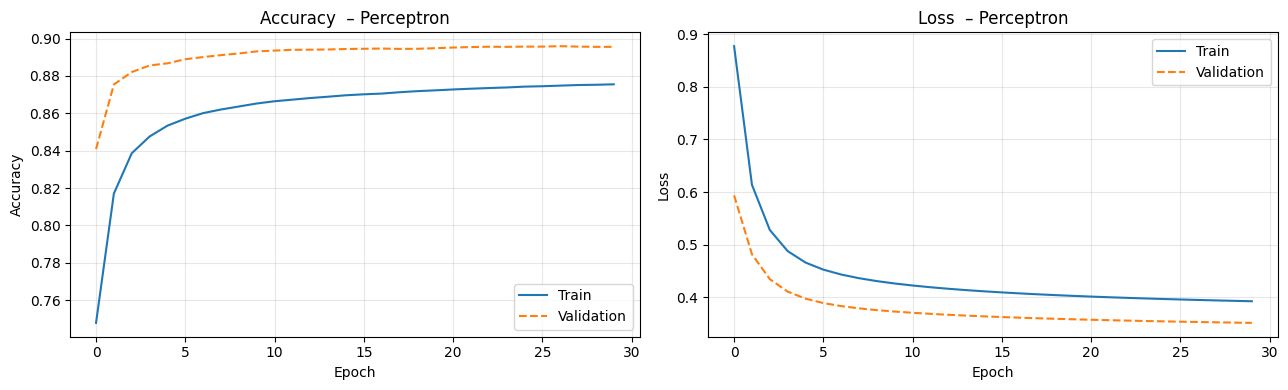


Perceptron - test set:
  Accuracy=0.9020 | Loss=0.3370 | F1-macro=0.5431 | Precision=0.7142 | Recall=0.4971


In [ ]:
plot_history(history_p, '– Perceptron')

print("\nPerceptron - test set:")
acc_p, loss_p, f1_p, pre_p, rec_p, ypred_p = evaluate_model(model_p)
store('Perceptron', acc_p, f1_p, pre_p, rec_p,
      len(history_p.history['loss']), 'no hidden layers')

---
## 7.MLP
- added hidden layers with ReLU activations

In [ ]:
model_mlp = Sequential([
    #Hidden layer 1
    Dense(256, activation='relu', input_shape=(187,)),
    BatchNormalization(),
    Dropout(0.3),

    #Hidden layer 2
    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.3),

    #Hidden layer 3
    Dense(64, activation='relu'),
    Dropout(0.2),

    #Output layer
    Dense(5, activation='softmax')
], name='MLP_baseline')

model_mlp.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
model_mlp.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "MLP_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 256)            │        48,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_6 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,141 (356.02 KB)

 Trainable params: 90,373 (353.02 KB)

 Non-trainable params: 768 (3.00 KB)

In [ ]:
#Training MLP
history_mlp = model_mlp.fit(
    X_train_aug, y_train_aug_cat,
    validation_data=(X_val_norm, y_val_cat),
    epochs=50, batch_size=256,
    callbacks=get_callbacks(), verbose=1
)


Epoch 1/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - accuracy: 0.8869 - loss: 0.3650 - val_accuracy: 0.9340 - val_loss: 0.2110 - learning_rate: 0.0010
Epoch 2/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - accuracy: 0.9342 - loss: 0.2211 - val_accuracy: 0.9584 - val_loss: 0.1420 - learning_rate: 0.0010
Epoch 3/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9438 - loss: 0.1894 - val_accuracy: 0.9619 - val_loss: 0.1307 - learning_rate: 0.0010
Epoch 4/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9489 - loss: 0.1725 - val_accuracy: 0.9669 - val_loss: 0.1214 - learning_rate: 0.0010
Epoch 5/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9528 - loss: 0.1580 - val_accuracy: 0.9684 - val_loss: 0.1142 - learning_rate: 0.0010
Epoch 6/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9564 - loss: 0.1482 - val_accuracy: 0.9683 - val_loss: 0.1153 - learning_rate: 0.0010
Epoch 7/50
330/330 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9575 - loss: 0.

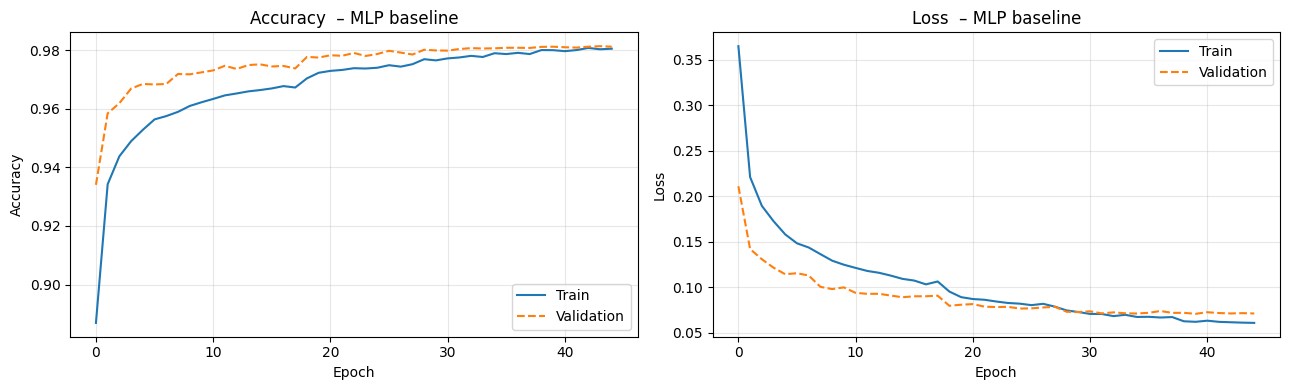


MLP baseline – test set:
  Accuracy=0.9821 | Loss=0.0665 | F1-macro=0.9065 | Precision=0.9413 | Recall=0.8784


In [ ]:
plot_history(history_mlp, '– MLP baseline')

print("\nMLP baseline – test set:")
acc_mlp, _, f1_mlp, pre_mlp, rec_mlp, ypred_mlp = evaluate_model(model_mlp)
store('MLP_baseline', acc_mlp, f1_mlp, pre_mlp, rec_mlp,
      len(history_mlp.history['loss']), '3 hidden, Dropout, BN')

---
## 8. MLP Versions

### 8a. Hidden layers

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Epoch 40: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
Restoring model weights from the end of the best epoch: 49.


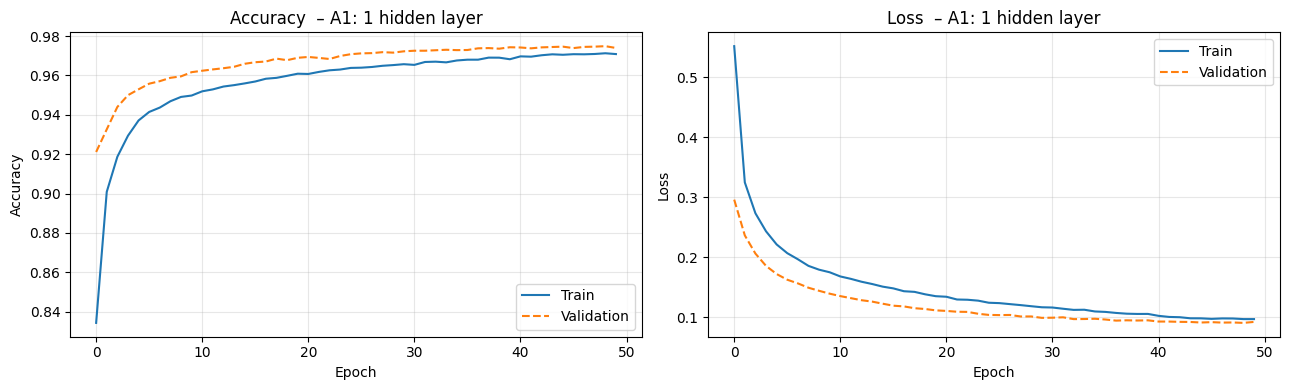

A1 – test set:
  Accuracy=0.9736 | Loss=0.0920 | F1-macro=0.8662 | Precision=0.9257 | Recall=0.8239


In [ ]:
#1 hidden layer
model_A1 = Sequential([
    Dense(128, activation='relu', input_shape=(187,)),
    Dropout(0.2),
    Dense(5, activation='softmax')
], name='A1_depth1')
model_A1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

#Training
history_A1 = model_A1.fit(
    X_train_aug, y_train_aug_cat,
    validation_data=(X_val_norm, y_val_cat),
    epochs=50, batch_size=256, callbacks=get_callbacks(), verbose=0
)
plot_history(history_A1, '– A1: 1 hidden layer')
print("A1 – test set:"); acc_A1,_,f1_A1,pre_A1,rec_A1,_ = evaluate_model(model_A1)
store('A1_depth1', acc_A1, f1_A1, pre_A1, rec_A1, len(history_A1.history['loss']), '1 hidden')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8543 - loss: 0.4769 - val_accuracy: 0.9488 - val_loss: 0.1937 - learning_rate: 0.0010
Epoch 2/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9303 - loss: 0.2449 - val_accuracy: 0.9596 - val_loss: 0.1471 - learning_rate: 0.0010
Epoch 3/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.9435 - loss: 0.2027 - val_accuracy: 0.9613 - val_loss: 0.1333 - learning_rate: 0.0010
Epoch 4/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - accuracy: 0.9509 - loss: 0.1757 - val_accuracy: 0.9659 - val_loss: 0.1179 - learning_rate: 0.0010
Epoch 5/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9545 - loss: 0.1621 - val_accuracy: 0.9695 - val_loss: 0.1108 - learning_rate: 0.0010
Epoch 6/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.9573 - loss: 0.1525 - val_accuracy: 0.9675 - val_loss: 0.1110 - learning_rate: 0.0010
Epoch 7/50
329/329 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9609 - loss: 0.

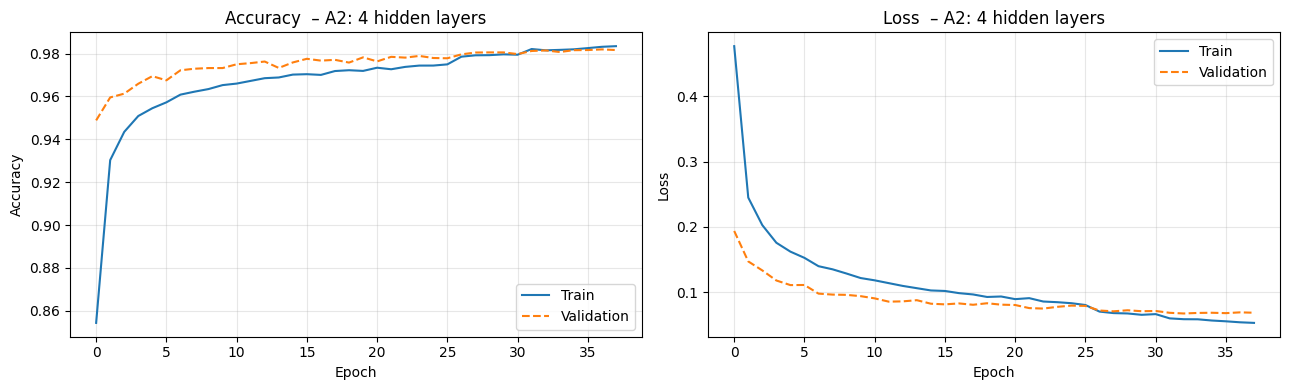

A2 – test set:
  Accuracy=0.9809 | Loss=0.0689 | F1-macro=0.9063 | Precision=0.9482 | Recall=0.8738


In [ ]:
#4 hidden layers
model_A2 = Sequential([
    Dense(256, activation='relu', input_shape=(187,)),
    Dropout(0.2),
    Dense(128, activation='relu'),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(5, activation='softmax')
], name='A2_depth4')
model_A2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

#Training
history_A2 = model_A2.fit(
    X_train_aug, y_train_aug_cat,
    validation_data=(X_val_norm, y_val_cat),
    epochs=50, batch_size=256, callbacks=get_callbacks(),
)
plot_history(history_A2, '– A2: 4 hidden layers')
print("A2 – test set:"); acc_A2,_,f1_A2,pre_A2,rec_A2,_ = evaluate_model(model_A2)
store('A2_depth4', acc_A2, f1_A2, pre_A2, rec_A2, len(history_A2.history['loss']), '4 hidden')


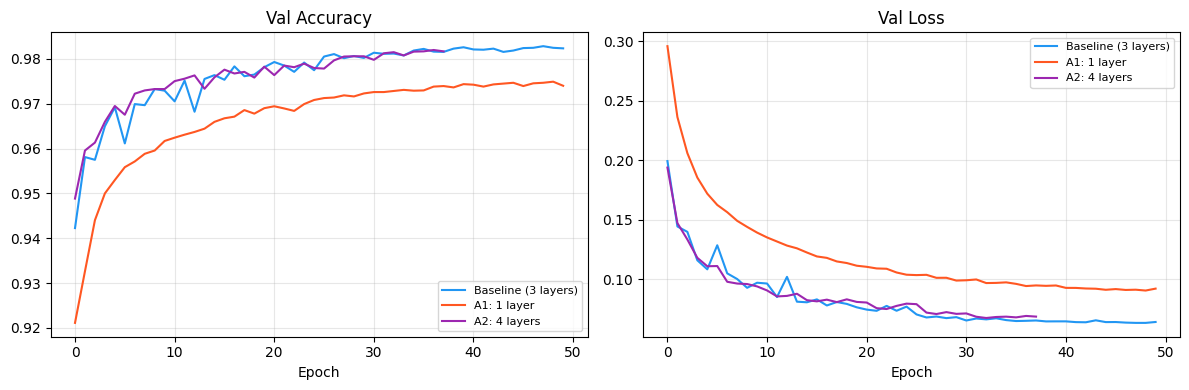

In [ ]:
# Summary plot (depth)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for hist, name, col in [
        (history_mlp, 'Baseline (3 layers)', '#2196F3'),
        (history_A1,  'A1: 1 layer',         '#FF5722'),
        (history_A2,  'A2: 4 layers',        '#9C27B0')]:

    axes[0].plot(
        hist.history['val_accuracy'],
        label=name,
        color=col
    )

    axes[1].plot(
        hist.history['val_loss'],
        label=name,
        color=col
    )

axes[0].set_title('Val Accuracy')
axes[1].set_title('Val Loss')

for ax in axes:
    ax.set_xlabel('Epoch')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 8b. Batch Size

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
2636/2636 ━━━━━━━━━━━━━━━━━━━━ 16s 5ms/step - accuracy: 0.8936 - loss: 0.3437 - val_accuracy: 0.9508 - val_loss: 0.1693 - learning_rate: 0.0010
Epoch 2/50
2636/2636 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9281 - loss: 0.2358 - val_accuracy: 0.9574 - val_loss: 0.1636 - learning_rate: 0.0010
Epoch 3/50
2636/2636 ━━━━━━━━━━━━━━━━━━━━ 15s 6ms/step - accuracy: 0.9362 - loss: 0.2113 - val_accuracy: 0.9604 - val_loss: 0.1425 - learning_rate: 0.0010
Epoch 4/50
2636/2636 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9410 - loss: 0.1943 - val_accuracy: 0.9632 - val_loss: 0.1297 - learning_rate: 0.0010
Epoch 5/50
2636/2636 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9455 - loss: 0.1803 - val_accuracy: 0.9681 - val_loss: 0.1133 - learning_rate: 0.0010
Epoch 6/50
2636/2636 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9492 - loss: 0.1714 - val_accuracy: 0.9686 - val_loss: 0.1181 - learning_rate: 0.0010
Epoch 7/50
2636/2636 ━━━━━━━━━━━━━━━━━━━━ 13s 5ms/step - accuracy: 0.9

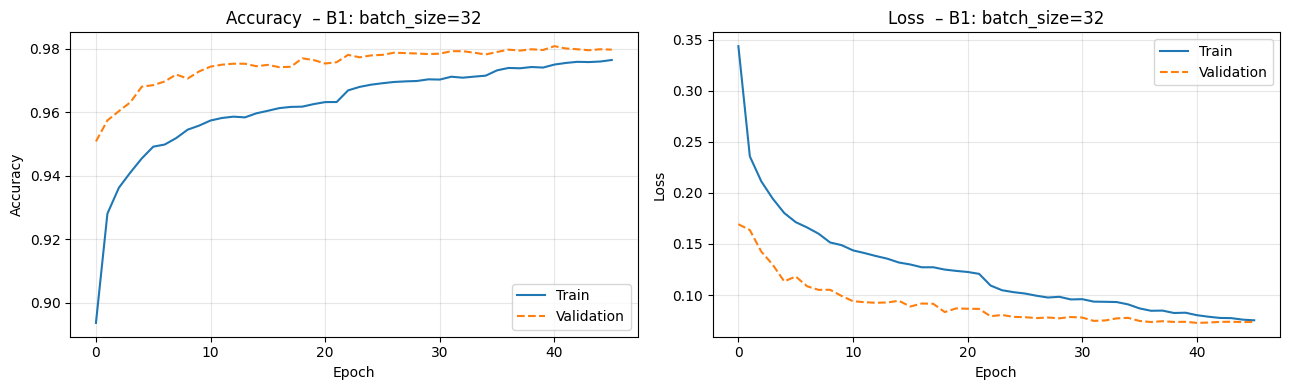

B1 – test set:
  Accuracy=0.9795 | Loss=0.0713 | F1-macro=0.8885 | Precision=0.9294 | Recall=0.8567


In [ ]:
#batch_size = 32
model_B1 = Sequential([
    Dense(256, activation='relu', input_shape=(187,)), BatchNormalization(), Dropout(0.3),
    Dense(128, activation='relu'), BatchNormalization(), Dropout(0.3),
    Dense(64,  activation='relu'), Dropout(0.2),
    Dense(5,   activation='softmax')
], name='B1_batch32')
model_B1.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

#Training
history_B1 = model_B1.fit(
    X_train_aug, y_train_aug_cat,
    validation_data=(X_val_norm, y_val_cat),
    epochs=50, batch_size=32, callbacks=get_callbacks(),
)
plot_history(history_B1, '– B1: batch_size=32')
print("B1 – test set:"); acc_B1,_,f1_B1,pre_B1,rec_B1,_ = evaluate_model(model_B1)
store('B1_batch32', acc_B1, f1_B1, pre_B1, rec_B1, len(history_B1.history['loss']), 'batch=32')

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 7s 27ms/step - accuracy: 0.8649 - loss: 0.4324 - val_accuracy: 0.8979 - val_loss: 0.3434 - learning_rate: 0.0010
Epoch 2/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.9288 - loss: 0.2454 - val_accuracy: 0.9364 - val_loss: 0.2019 - learning_rate: 0.0010
Epoch 3/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9408 - loss: 0.2036 - val_accuracy: 0.9578 - val_loss: 0.1444 - learning_rate: 0.0010
Epoch 4/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9459 - loss: 0.1856 - val_accuracy: 0.9640 - val_loss: 0.1253 - learning_rate: 0.0010
Epoch 5/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - accuracy: 0.9496 - loss: 0.1698 - val_accuracy: 0.9638 - val_loss: 0.1284 - learning_rate: 0.0010
Epoch 6/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.9521 - loss: 0.1616 - val_accuracy: 0.9662 - val_loss: 0.1174 - learning_rate: 0.0010
Epoch 7/50
165/165 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.9560 - loss: 0.

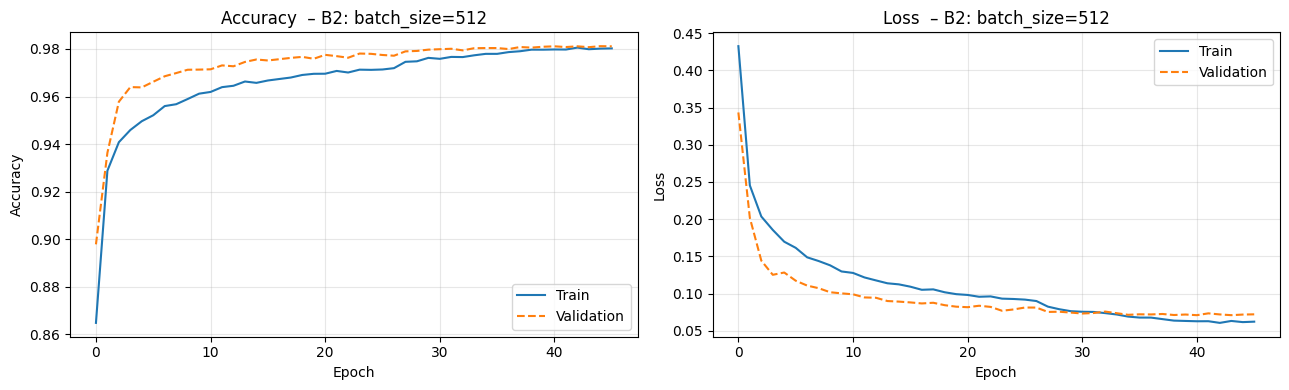

B2 – test set:
  Accuracy=0.9823 | Loss=0.0672 | F1-macro=0.9071 | Precision=0.9401 | Recall=0.8797


In [ ]:
#batch_size = 512
model_B2 = Sequential([
    Dense(256, activation='relu', input_shape=(187,)), BatchNormalization(), Dropout(0.3),
    Dense(128, activation='relu'), BatchNormalization(), Dropout(0.3),
    Dense(64,  activation='relu'), Dropout(0.2),
    Dense(5,   activation='softmax')
], name='B2_batch512')
model_B2.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

#Training
history_B2 = model_B2.fit(
    X_train_aug, y_train_aug_cat,
    validation_data=(X_val_norm, y_val_cat),
    epochs=50, batch_size=512, callbacks=get_callbacks(),
)
plot_history(history_B2, '– B2: batch_size=512')
print("B2 – test set:"); acc_B2,_,f1_B2,pre_B2,rec_B2,_ = evaluate_model(model_B2)
store('B2_batch512', acc_B2, f1_B2, pre_B2, rec_B2, len(history_B2.history['loss']), 'batch=512')

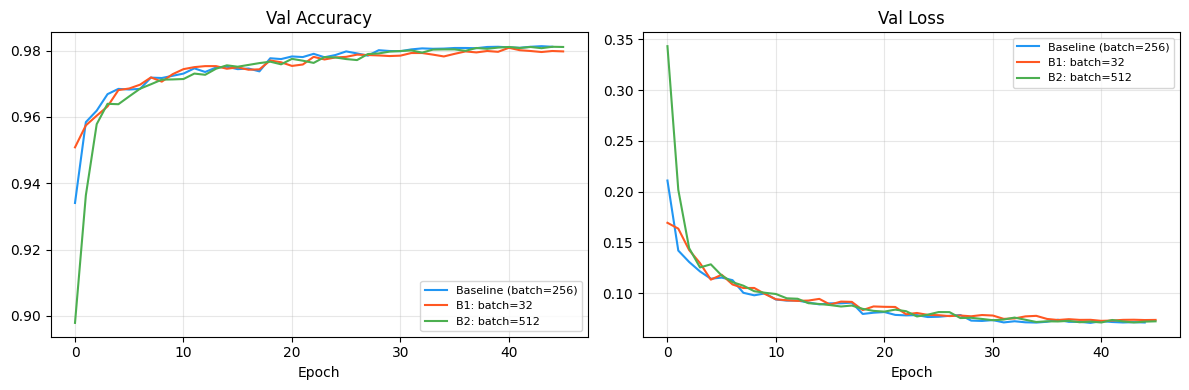

In [ ]:
# Summary plot (batch size)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for hist, name, col in [
        (history_mlp, 'Baseline (batch=256)', '#2196F3'),
        (history_B1,  'B1: batch=32',          '#FF5722'),
        (history_B2,  'B2: batch=512',          '#4CAF50')
        ]:
    axes[0].plot(hist.history['val_accuracy'], label=name, color=col)
    axes[1].plot(hist.history['val_loss'],     label=name, color=col)
axes[0].set_title('Val Accuracy')
axes[1].set_title('Val Loss')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

---
## 8. 1D CNN

In [ ]:
# Reshape for CNN
X_train_cnn = X_train_aug.reshape(-1, 187, 1)
X_val_cnn   = X_val_norm.reshape(-1, 187, 1)
X_test_cnn  = X_test_norm.reshape(-1, 187, 1)
print("CNN shapes:", X_train_cnn.shape, X_val_cnn.shape, X_test_cnn.shape)

CNN shapes: (84341, 187, 1) (16450, 187, 1) (16451, 187, 1)


In [ ]:
model_cnn = Sequential([
    Conv1D(32, kernel_size=5, activation='relu', padding='same', input_shape=(187, 1)),
    Conv1D(32, kernel_size=5, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),
    Dropout(0.2),

    Conv1D(64, kernel_size=3, activation='relu', padding='same'),
    Conv1D(64, kernel_size=3, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),
    Dropout(0.2),

    Conv1D(128, kernel_size=3, activation='relu', padding='same'),
    MaxPooling1D(pool_size=2),
    Dropout(0.2),

    GlobalAveragePooling1D(),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(5, activation='softmax')
], name='CNN_1D')

model_cnn.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])
model_cnn.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "CNN_1D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 187, 32)        │           192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 187, 32)        │         5,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 93, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 93, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_2 (Conv1D)               │ (None, 93, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_3 (Conv1D)               │ (None, 93, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_1 (MaxPooling1D)  │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 46, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_4 (Conv1D)               │ (None, 46, 128)        │        24,704 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_2 (MaxPooling1D)  │ (None, 23, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 23, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,189 (223.39 KB)

 Trainable params: 57,189 (223.39 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Training
history_cnn = model_cnn.fit(
    X_train_cnn, y_train_aug_cat,
    validation_data=(X_val_cnn, y_val_cat),
    epochs=50, batch_size=128,
    callbacks=get_callbacks(), verbose=1
)

Epoch 1/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 82s 121ms/step - accuracy: 0.8159 - loss: 0.6118 - val_accuracy: 0.9209 - val_loss: 0.3104 - learning_rate: 0.0010
Epoch 2/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 79s 120ms/step - accuracy: 0.8965 - loss: 0.3571 - val_accuracy: 0.9366 - val_loss: 0.2267 - learning_rate: 0.0010
Epoch 3/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 83s 121ms/step - accuracy: 0.9154 - loss: 0.2859 - val_accuracy: 0.9401 - val_loss: 0.1926 - learning_rate: 0.0010
Epoch 4/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 79s 120ms/step - accuracy: 0.9258 - loss: 0.2467 - val_accuracy: 0.9498 - val_loss: 0.1672 - learning_rate: 0.0010
Epoch 5/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 78s 118ms/step - accuracy: 0.9336 - loss: 0.2233 - val_accuracy: 0.9520 - val_loss: 0.1659 - learning_rate: 0.0010
Epoch 6/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 83s 120ms/step - accuracy: 0.9380 - loss: 0.2085 - val_accuracy: 0.9524 - val_loss: 0.1605 - learning_rate: 0.0010
Epoch 7/50
659/659 ━━━━━━━━━━━━━━━━━━━━ 82s 120ms/step - accuracy: 0.9

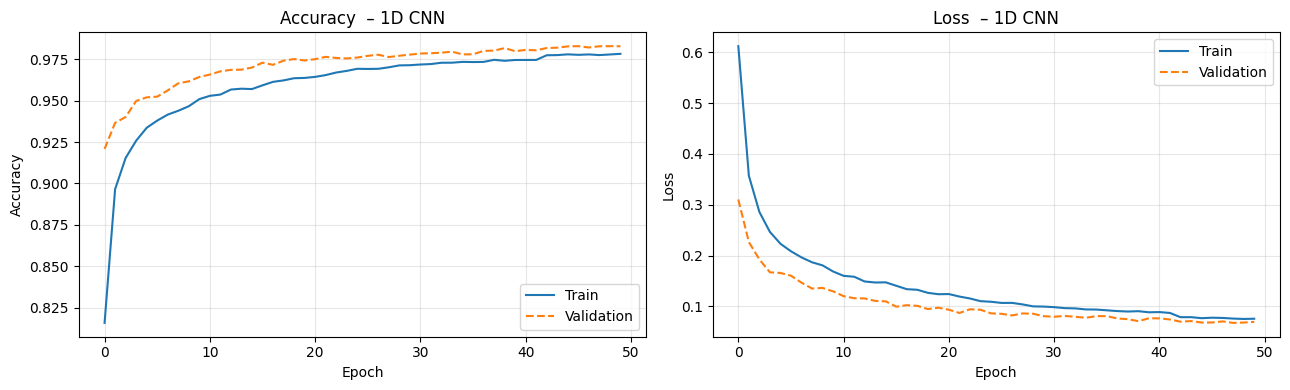


1D CNN – test set:
  Accuracy=0.9824 | Loss=0.0650 | F1-macro=0.9079 | Precision=0.9384 | Recall=0.8838


In [ ]:
plot_history(history_cnn, '– 1D CNN')

print("\n1D CNN – test set:")
acc_cnn,_,f1_cnn,pre_cnn,rec_cnn,ypred_cnn = evaluate_model(
    model_cnn, X_test_cnn, y_test_raw, y_test_cat)
store('CNN_1D', acc_cnn, f1_cnn, pre_cnn, rec_cnn,
      len(history_cnn.history['loss']), '3 conv blocks')

Confusion matrix – CNN_1D (test set):


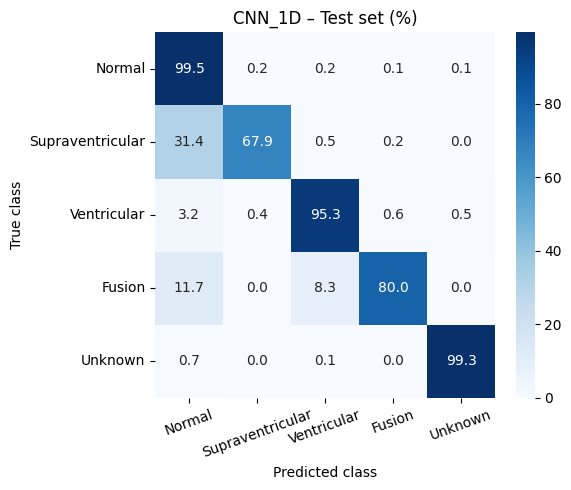

In [ ]:
# Confusion matrix - CNN
print("Confusion matrix – CNN_1D (test set):")
plot_confusion_matrix(y_test_raw, ypred_cnn, 'CNN_1D – Test set')

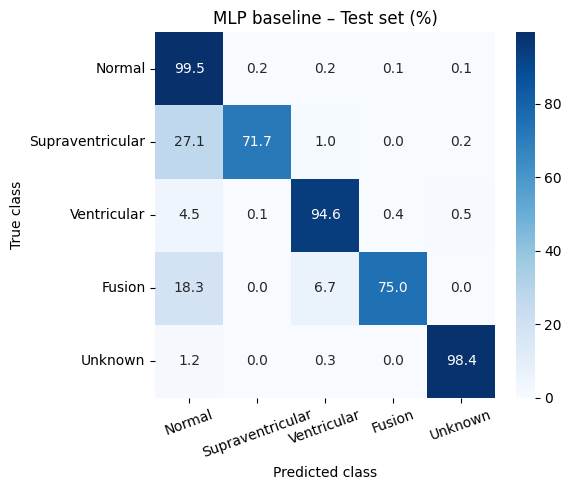

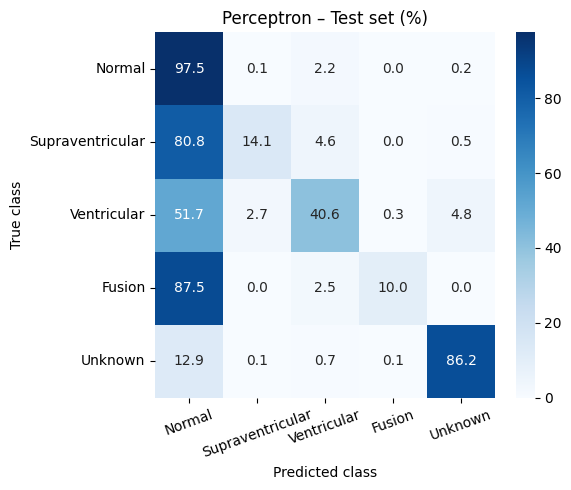

In [ ]:
# Confusion matrix – MLP baseline
plot_confusion_matrix(y_test_raw, ypred_mlp, 'MLP baseline – Test set')

# Confusion matrix – Perceptron
plot_confusion_matrix(y_test_raw, ypred_p, 'Perceptron – Test set')

## 9. Comparison

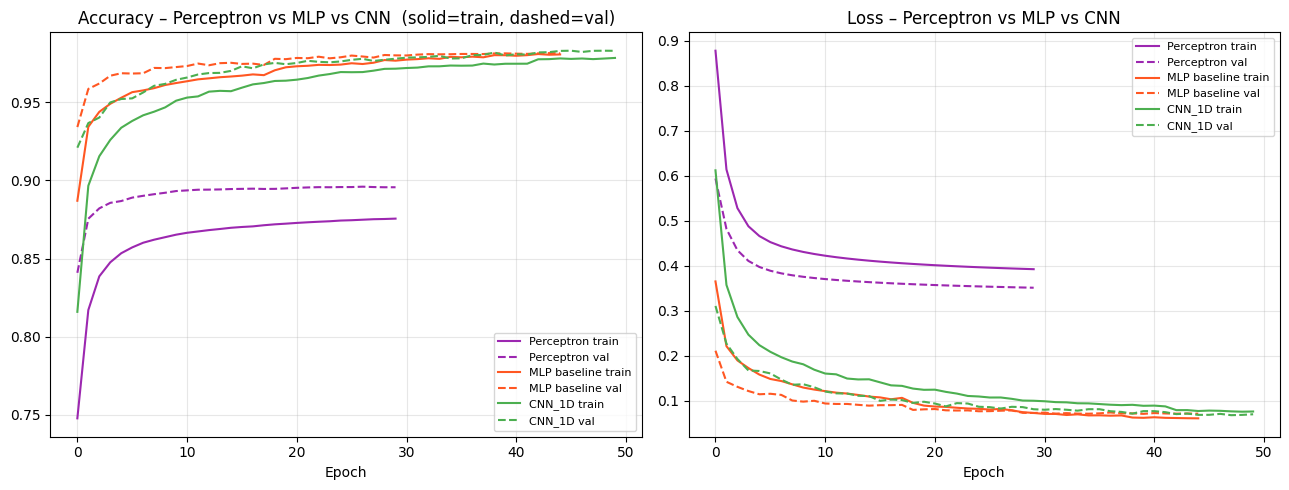

In [ ]:
# Comparison: Perceptron / MLP baseline / CNN
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for hist, name, col in [
        (history_p,   'Perceptron',    '#9C27B0'),
        (history_mlp, 'MLP baseline',  '#FF5722'),
        (history_cnn, 'CNN_1D',        '#4CAF50')]:
    axes[0].plot(hist.history['accuracy'],     color=col, linestyle='-',  label=f'{name} train')
    axes[0].plot(hist.history['val_accuracy'], color=col, linestyle='--', label=f'{name} val')
    axes[1].plot(hist.history['loss'],         color=col, linestyle='-',  label=f'{name} train')
    axes[1].plot(hist.history['val_loss'],     color=col, linestyle='--', label=f'{name} val')

axes[0].set_title('Accuracy – Perceptron vs MLP vs CNN  (solid=train, dashed=val)')
axes[1].set_title('Loss – Perceptron vs MLP vs CNN')
for ax in axes:
    ax.set_xlabel('Epoch'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.show()

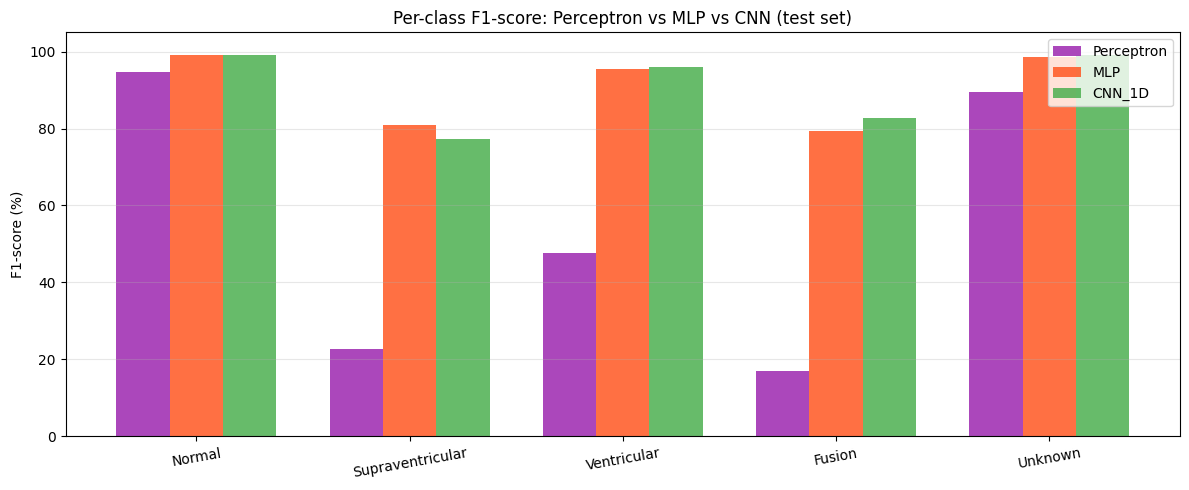

In [ ]:
# Per-class F1-score comparison (Perceptron, MLP, CNN)
x     = np.arange(5)
width = 0.25
fig, ax = plt.subplots(figsize=(12, 5))

for i, (name, ypred, col) in enumerate([
        ('Perceptron', ypred_p,   '#9C27B0'),
        ('MLP',        ypred_mlp, '#FF5722'),
        ('CNN_1D',     ypred_cnn, '#4CAF50')]):
    f1_pc = f1_score(y_test_raw, ypred, average=None, zero_division=0) * 100
    ax.bar(x + i*width, f1_pc, width, label=name, color=col, alpha=0.85)

ax.set_xticks(x + width)
ax.set_xticklabels(class_names.values(), rotation=10)
ax.set_ylabel('F1-score (%)'); ax.set_ylim(0, 105)
ax.set_title('Per-class F1-score: Perceptron vs MLP vs CNN (test set)')
ax.legend(); ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout(); plt.show()